In [ ]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  ★ 用户参数区
# ============================================================
N_ORDER   = 1
CAT_TYPE  = "odd"
N_DIM     = 40

G_FIXED   = 1.6          # ★ 固定 g

ALPHA_IN_MIN  = 0.5
ALPHA_IN_MAX  = 2.0
ALPHA_IN_NPTS = 20

ALPHA_TARGET_MAX_OFFSET = 3.0

RESTART_SEEDS = [42, 123, 7]

SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL = 150
DE_POPSIZE_SMALL = 20
DE_MAXITER_LARGE = 80
DE_POPSIZE_LARGE = 12

N_WORKERS = 4
# ============================================================


def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs


def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()


def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out


def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv


def _optimize_one(alpha_in, g_fixed, n, cat_type, N_dim,
                  alpha_tgt_max_offset, de_maxiter, de_popsize,
                  restart_seeds, small_alpha_threshold,
                  de_maxiter_small, de_popsize_small):
    """
    g 固定，只优化 [alpha_target, r]。
    """
    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(
        alpha_in, n, cat_type, N_dim)

    # g 固定，提前算好输出态向量（在所有 cost() 调用里复用）
    psi_out = fast_catalysis_vec(g_fixed, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter
    popsize  = de_popsize_small if is_small else de_popsize

    bounds = [
        (alpha_in + 0.05, alpha_in + alpha_tgt_max_offset),  # alpha_target
        (0.0, 2.0),                                           # r
    ]

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)


def run_scan_and_plot():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)

    print("╔══════════════════════════════════════════════════════════╗")
    print(f"  m=n={N_ORDER} | {CAT_TYPE} | g 固定 = {G_FIXED}")
    print(f"  优化变量: alpha_target, r  |  重启种子: {RESTART_SEEDS}")
    print(f"  小 α_in (<{SMALL_ALPHA_THRESHOLD}): maxiter={DE_MAXITER_SMALL}, popsize={DE_POPSIZE_SMALL}")
    print("╚══════════════════════════════════════════════════════════╝\n")

    raw_results = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
        delayed(_optimize_one)(
            ai, G_FIXED, N_ORDER, CAT_TYPE, N_DIM,
            ALPHA_TARGET_MAX_OFFSET,
            DE_MAXITER_LARGE, DE_POPSIZE_LARGE, RESTART_SEEDS,
            SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL
        )
        for ai in alpha_in_arr
    )

    raw_results.sort(key=lambda r: r[0])
    alpha_in_arr   = np.array([r[0] for r in raw_results])
    fidelities     = np.array([r[1] for r in raw_results])
    opt_alpha_tgts = np.array([r[2] for r in raw_results])
    opt_rs         = np.array([r[3] for r in raw_results])
    amplifications = opt_alpha_tgts / alpha_in_arr

    print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>5}  {'F':>7}  {'r':>6}")
    print(f"  {'-'*6}  {'-'*6}  {'-'*5}  {'-'*7}  {'-'*6}")
    for r in raw_results:
        ai, F, at, rv = r
        print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:5.3f}  {F:7.4f}  {rv:6.3f}")

    # ── 两张图并排 ──
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    fig.subplots_adjust(wspace=0.32)

    ax1.plot(alpha_in_arr, fidelities, 'o-', color='royalblue', lw=2, ms=5)
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'Fidelity $F$', fontsize=14)
    ax1.set_title(rf'Fidelity  ($m=n={N_ORDER}$, $g={G_FIXED}$, {CAT_TYPE} cat)',
                  fontsize=13)
    ax1.set_ylim(max(0, fidelities.min() - 0.05), 1.02)
    ax1.grid(True, ls='--', alpha=0.4)

    ax2.plot(alpha_in_arr, amplifications, 's-', color='seagreen', lw=2, ms=5)
    ax2.axhline(1.0, color='grey', ls=':', lw=1.2, label='No amplification')
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\alpha_{\mathrm{target}}\,/\,\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_title(rf'Amplification  ($g={G_FIXED}$)', fontsize=13)
    ax2.legend(fontsize=10)
    ax2.grid(True, ls='--', alpha=0.4)

    fig.suptitle(
        rf"Catalysis: $m=n={N_ORDER}$, $g={G_FIXED}$ (fixed), {CAT_TYPE.capitalize()} Cat",
        fontsize=14)

    plt.savefig('catalysis_result.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_result.png', bbox_inches='tight', dpi=150)
    plt.show()


run_scan_and_plot()

╔══════════════════════════════════════════════════════════╗
  m=n=1 | odd | g 固定 = 1.6
  优化变量: alpha_target, r  |  重启种子: [42, 123, 7]
  小 α_in (<0.8): maxiter=150, popsize=20
╚══════════════════════════════════════════════════════════╝



[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



  Running case: m=n=1, g=1.6


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   56.0s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.4min remaining:    9.5s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.5min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.577   1.925 ▲   1.0000   0.034
   0.363   0.699   1.926 ▲   1.0000   0.050
   0.426   0.822   1.928 ▲   1.0000   0.069
   0.489   0.944   1.929 ▲   1.0000   0.090
   0.553   1.068   1.932 ▲   1.0000   0.114
   0.616   1.192   1.936 ▲   1.0000   0.141
   0.679   1.318   1.941 ▲   0.9999   0.170
   0.742   1.443   1.945 ▲   0.9997   0.201
   0.805   1.568   1.947 ▲   0.9993   0.233
   0.868   1.691   1.947 ▲   0.9985   0.264
   0.932   1.808   1.941 ▲   0.9971   0.293
   0.995   1.918   1.928 ▲   0.9951   0.319
   1.058   2.018   1.908 ▲   0.9923   0.340
   1.121   2.108   1.880 ▲   0.9888   0.358
   1.184   2.186   1.846 ▲   0.9848   0.372
   1.247   2.255   1.808 ▲   0.9805   0.381
   1.311   2.314   1.766 ▲   0.9762   0.387
   1.374   2.366   1.722 ▲   0.9721   0.391
   1.437   2.410   1.678 ▲   0.9683   0.392
   1.500   2.450   1.633 ▲   0.9651   0.391

  Running case: m=n=2, g=1.36


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   50.4s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.2min remaining:    8.1s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.3min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.457   1.524 ▲   1.0000   0.025
   0.363   0.554   1.526 ▲   1.0000   0.037
   0.426   0.651   1.527 ▲   1.0000   0.050
   0.489   0.748   1.528 ▲   1.0000   0.066
   0.553   0.845   1.530 ▲   1.0000   0.085
   0.616   0.944   1.533 ▲   1.0000   0.105
   0.679   1.043   1.536 ▲   1.0000   0.128
   0.742   1.143   1.541 ▲   1.0000   0.153
   0.805   1.245   1.547 ▲   1.0000   0.180
   0.868   1.349   1.554 ▲   0.9999   0.209
   0.932   1.455   1.562 ▲   0.9999   0.241
   0.995   1.563   1.571 ▲   0.9997   0.273
   1.058   1.672   1.581 ▲   0.9994   0.308
   1.121   1.783   1.590 ▲   0.9989   0.343
   1.184   1.893   1.599 ▲   0.9981   0.378
   1.247   2.002   1.605 ▲   0.9969   0.412
   1.311   2.109   1.609 ▲   0.9951   0.445
   1.374   2.212   1.610 ▲   0.9927   0.477
   1.437   2.311   1.609 ▲   0.9896   0.506
   1.500   2.407   1.605 ▲   0.9857   0.535

  Running case: m=n=3, g=4.5


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   54.5s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.4min remaining:    9.1s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.4min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.678   2.259 ▲   1.0000   0.049
   0.363   0.821   2.261 ▲   1.0000   0.072
   0.426   0.966   2.265 ▲   1.0000   0.099
   0.489   1.112   2.271 ▲   1.0000   0.130
   0.553   1.259   2.278 ▲   0.9999   0.165
   0.616   1.408   2.287 ▲   0.9998   0.203
   0.679   1.558   2.295 ▲   0.9993   0.243
   0.742   1.706   2.299 ▲   0.9984   0.283
   0.805   1.848   2.295 ▲   0.9967   0.321
   0.868   1.980   2.280 ▲   0.9939   0.355
   0.932   2.099   2.253 ▲   0.9899   0.384
   0.995   2.203   2.215 ▲   0.9849   0.407
   1.058   2.295   2.169 ▲   0.9793   0.425
   1.121   2.374   2.118 ▲   0.9735   0.440
   1.184   2.444   2.064 ▲   0.9679   0.451
   1.247   2.506   2.009 ▲   0.9627   0.459
   1.311   2.561   1.954 ▲   0.9583   0.466
   1.374   2.612   1.901 ▲   0.9546   0.471
   1.437   2.659   1.850 ▲   0.9518   0.475
   1.500   2.703   1.802 ▲   0.9499   0.478

  Running case: m=n=4, g=2.6


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   49.6s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.2min remaining:    8.2s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.3min finished



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.467   1.555 ▲   1.0000   0.025
   0.363   0.564   1.554 ▲   1.0000   0.037
   0.426   0.664   1.557 ▲   1.0000   0.051
   0.489   0.763   1.559 ▲   1.0000   0.067
   0.553   0.862   1.561 ▲   1.0000   0.086
   0.616   0.963   1.563 ▲   1.0000   0.106
   0.679   1.064   1.567 ▲   1.0000   0.129
   0.742   1.167   1.573 ▲   1.0000   0.155
   0.805   1.272   1.580 ▲   1.0000   0.183
   0.868   1.380   1.589 ▲   1.0000   0.213
   0.932   1.490   1.599 ▲   1.0000   0.245
   0.995   1.604   1.612 ▲   0.9999   0.280
   1.058   1.721   1.627 ▲   0.9998   0.318
   1.121   1.844   1.644 ▲   0.9997   0.357
   1.184   1.970   1.663 ▲   0.9993   0.398
   1.247   2.101   1.684 ▲   0.9987   0.440
   1.311   2.236   1.706 ▲   0.9976   0.483
   1.374   2.375   1.729 ▲   0.9958   0.527
   1.437   2.520   1.754 ▲   0.9928   0.571
   1.500   2.669   1.779 ▲   0.9883   0.615


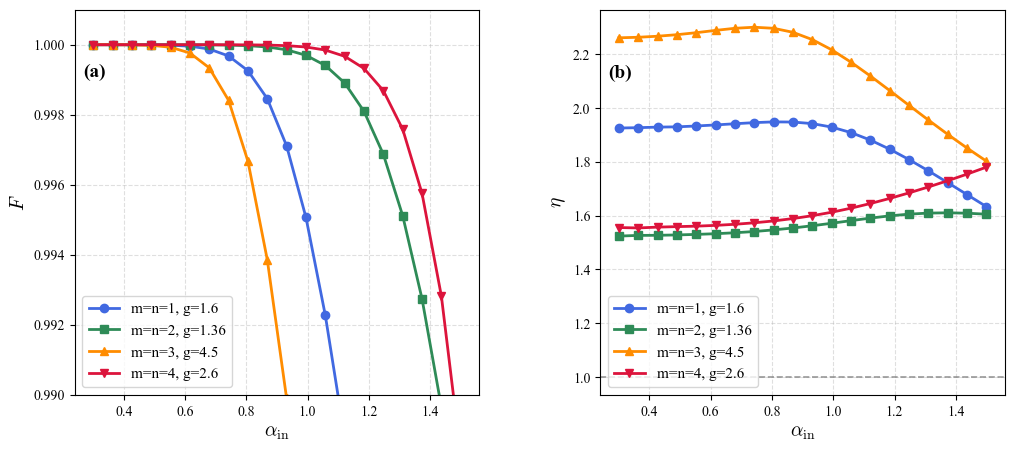

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用参数
# ============================================================
CAT_TYPE           = "odd"
N_DIM              = 50
ALPHA_IN_MIN       = 0.3
ALPHA_IN_MAX       = 1.5
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]
SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL   = 150
DE_POPSIZE_SMALL   = 20
DE_MAXITER_LARGE   = 80
DE_POPSIZE_LARGE   = 12
N_WORKERS          = 4

# ============================================================
#  定义四种需要比较的 case
# ============================================================
cases = [
    {
        'label'      : 'm=n=1, g=1.6',
        'n'          : 1,
        'g'          : 1.6,
        'allow_atten': True,
        'at_min'     : 0.05,
        'at_max'     : 5.0,
        'at_offset'  : None
    },
    {
        'label'      : 'm=n=2, g=1.36',
        'n'          : 2,
        'g'          : 1.36,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=3, g=4.5',
        'n'          : 3,
        'g'          : 4.5,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=4, g=2.6',
        'n'          : 4,
        'g'          : 2.6,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    }
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv

# ============================================================
#  优化单个 alpha_in（针对某一个 case）
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds,
                 small_alpha_threshold, de_maxiter_small, de_popsize_small,
                 de_maxiter_large, de_popsize_large):
    n           = case['n']
    g           = case['g']
    allow_atten = case['allow_atten']
    at_min      = case['at_min']
    at_max      = case['at_max']
    at_offset   = case['at_offset']
    cat_type    = CAT_TYPE

    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, cat_type, N_dim)
    psi_out = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    if allow_atten:
        bounds = [
            (at_min, at_max),
            (0.0, 2.0)
        ]
    else:
        bounds = [
            (alpha_in + 0.05, alpha_in + at_offset),
            (0.0, 2.0)
        ]

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter_large
    popsize  = de_popsize_small if is_small else de_popsize_large

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)

# ============================================================
#  主函数
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    all_results = {}

    for case in cases:
        label = case['label']
        print(f"\n{'='*60}")
        print(f"  Running case: {label}")
        print(f"{'='*60}")

        raw = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
            delayed(optimize_one)(
                ai, case, N_DIM, RESTART_SEEDS,
                SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL,
                DE_MAXITER_LARGE, DE_POPSIZE_LARGE
            )
            for ai in alpha_in_arr
        )

        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # ========================================================
    #  画图：两个子图
    # ========================================================
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    fig.subplots_adjust(wspace=0.3)

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax1.plot(alpha_vals, fids, marker=marker, color=color,
                 lw=2, ms=6, label=label)
        ax2.plot(alpha_vals, amps, marker=marker, color=color,
                 lw=2, ms=6, label=label)

    # ---- 左图：Fidelity ----
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax1.set_ylabel(r'$F$', fontsize=14)
    ax1.set_ylim(0.99, 1.001)
    ax1.grid(True, ls='--', alpha=0.4)
    ax1.legend(fontsize=11)
    
    # 🌟 新增：在 ax1 左上角添加 (a)
    # transform=ax1.transAxes 使用相对坐标 (0~1)，0.02, 0.95 确保固定在左上角
    ax1.text(0.02, 0.86, '(a)', transform=ax1.transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

    # ---- 右图：Amplification ----
    ax2.axhline(1.0, color='grey', ls='--', lw=1.2, alpha=0.8)
    atten_label = cases[0]['label']
    for d in all_results[atten_label]:
        ai = d[0]; amp = d[2] / ai
        if amp < 1.0:
            ax2.fill_between([ai - 0.02, ai + 0.02], amp, 1.0,
                             color='tomato', alpha=0.15, edgecolor=None)
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=14)
    ax2.set_ylabel(r'$\eta$', fontsize=14)
    ax2.legend(fontsize=11)
    ax2.grid(True, ls='--', alpha=0.4)

    # 🌟 新增：在 ax2 左上角添加 (b)
    ax2.text(0.02, 0.86, '(b)', transform=ax2.transAxes, 
             fontsize=14, fontweight='bold', va='top', ha='left')

    plt.savefig('catalysis_comparison.pdf', bbox_inches='tight', dpi=150)
    plt.savefig('catalysis_comparison.png', bbox_inches='tight', dpi=150)
    plt.show()

if __name__ == '__main__':
    main()


  Running case: m=n=1, g=1.6


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   47.0s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.1min remaining:    7.3s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.1min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.577   1.925 ▲   1.0000   0.034
   0.363   0.699   1.926 ▲   1.0000   0.050
   0.426   0.822   1.928 ▲   1.0000   0.069
   0.489   0.944   1.929 ▲   1.0000   0.090
   0.553   1.068   1.932 ▲   1.0000   0.114
   0.616   1.192   1.936 ▲   1.0000   0.141
   0.679   1.318   1.941 ▲   0.9999   0.170
   0.742   1.443   1.945 ▲   0.9997   0.201
   0.805   1.568   1.947 ▲   0.9993   0.233
   0.868   1.691   1.947 ▲   0.9985   0.264
   0.932   1.808   1.941 ▲   0.9971   0.293
   0.995   1.918   1.928 ▲   0.9951   0.319
   1.058   2.018   1.908 ▲   0.9923   0.340
   1.121   2.108   1.880 ▲   0.9888   0.358
   1.184   2.186   1.846 ▲   0.9848   0.372
   1.247   2.255   1.808 ▲   0.9805   0.381
   1.311   2.314   1.766 ▲   0.9762   0.387
   1.374   2.366   1.722 ▲   0.9721   0.391
   1.437   2.410   1.678 ▲   0.9683   0.392
   1.500   2.450   1.633 ▲   0.9651   0.391

  Running case: m=n=2, g=1.36


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   34.8s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:   53.3s remaining:    5.8s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:   54.9s finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.457   1.524 ▲   1.0000   0.025
   0.363   0.554   1.526 ▲   1.0000   0.037
   0.426   0.651   1.527 ▲   1.0000   0.050
   0.489   0.748   1.528 ▲   1.0000   0.066
   0.553   0.845   1.530 ▲   1.0000   0.085
   0.616   0.944   1.533 ▲   1.0000   0.105
   0.679   1.043   1.536 ▲   1.0000   0.128
   0.742   1.143   1.541 ▲   1.0000   0.153
   0.805   1.245   1.547 ▲   1.0000   0.180
   0.868   1.349   1.554 ▲   0.9999   0.209
   0.932   1.455   1.562 ▲   0.9999   0.241
   0.995   1.563   1.571 ▲   0.9997   0.273
   1.058   1.672   1.581 ▲   0.9994   0.308
   1.121   1.783   1.590 ▲   0.9989   0.343
   1.184   1.893   1.599 ▲   0.9981   0.378
   1.247   2.002   1.605 ▲   0.9969   0.412
   1.311   2.109   1.609 ▲   0.9951   0.445
   1.374   2.212   1.610 ▲   0.9927   0.477
   1.437   2.311   1.609 ▲   0.9896   0.506
   1.500   2.407   1.605 ▲   0.9857   0.535

  Running case: m=n=3, g=4.5


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   40.8s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:  1.1min remaining:    7.1s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.1min finished
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.678   2.259 ▲   1.0000   0.049
   0.363   0.821   2.261 ▲   1.0000   0.072
   0.426   0.966   2.265 ▲   1.0000   0.099
   0.489   1.112   2.271 ▲   1.0000   0.130
   0.553   1.259   2.278 ▲   0.9999   0.165
   0.616   1.408   2.287 ▲   0.9998   0.203
   0.679   1.558   2.295 ▲   0.9993   0.243
   0.742   1.706   2.299 ▲   0.9984   0.283
   0.805   1.848   2.295 ▲   0.9967   0.321
   0.868   1.980   2.280 ▲   0.9939   0.355
   0.932   2.099   2.253 ▲   0.9899   0.384
   0.995   2.203   2.215 ▲   0.9849   0.407
   1.058   2.295   2.169 ▲   0.9793   0.425
   1.121   2.374   2.118 ▲   0.9735   0.440
   1.184   2.444   2.064 ▲   0.9679   0.451
   1.247   2.506   2.009 ▲   0.9627   0.459
   1.311   2.561   1.954 ▲   0.9583   0.466
   1.374   2.612   1.901 ▲   0.9546   0.471
   1.437   2.659   1.850 ▲   0.9518   0.475
   1.500   2.703   1.802 ▲   0.9499   0.478

  Running case: m=n=4, g=2.6


[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   37.2s
[Parallel(n_jobs=4)]: Done  18 out of  20 | elapsed:   57.7s remaining:    6.3s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:  1.0min finished



    α_in   α_tgt     amp        F       r
  ------  ------  ------  -------  ------
   0.300   0.467   1.555 ▲   1.0000   0.025
   0.363   0.564   1.554 ▲   1.0000   0.037
   0.426   0.664   1.557 ▲   1.0000   0.051
   0.489   0.763   1.559 ▲   1.0000   0.067
   0.553   0.862   1.561 ▲   1.0000   0.086
   0.616   0.963   1.563 ▲   1.0000   0.106
   0.679   1.064   1.567 ▲   1.0000   0.129
   0.742   1.167   1.573 ▲   1.0000   0.155
   0.805   1.272   1.580 ▲   1.0000   0.183
   0.868   1.380   1.589 ▲   1.0000   0.213
   0.932   1.490   1.599 ▲   1.0000   0.245
   0.995   1.604   1.612 ▲   0.9999   0.280
   1.058   1.721   1.627 ▲   0.9998   0.318
   1.121   1.844   1.644 ▲   0.9997   0.357
   1.184   1.970   1.663 ▲   0.9993   0.398
   1.247   2.101   1.684 ▲   0.9987   0.440
   1.311   2.236   1.706 ▲   0.9976   0.483
   1.374   2.375   1.729 ▲   0.9958   0.527
   1.437   2.520   1.754 ▲   0.9928   0.571
   1.500   2.669   1.779 ▲   0.9883   0.615

绘图完成！已保存为高清 catalysis_comparison.p

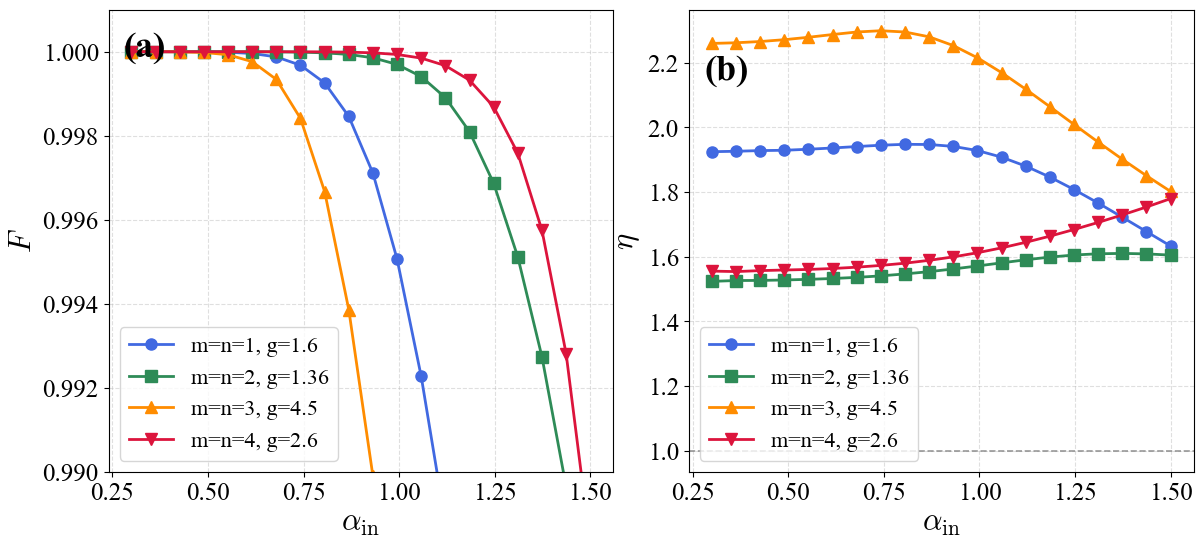

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import differential_evolution
from joblib import Parallel, delayed

mpl.rcParams['mathtext.fontset'] = 'cm'
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']

# ============================================================
#  通用参数
# ============================================================
CAT_TYPE           = "odd"
N_DIM              = 50
ALPHA_IN_MIN       = 0.3
ALPHA_IN_MAX       = 1.5
ALPHA_IN_NPTS      = 20
RESTART_SEEDS      = [42, 123, 7]
SMALL_ALPHA_THRESHOLD = 0.8
DE_MAXITER_SMALL   = 150
DE_POPSIZE_SMALL   = 20
DE_MAXITER_LARGE   = 80
DE_POPSIZE_LARGE   = 12
N_WORKERS          = 4

# ============================================================
#  定义四种需要比较的 case
# ============================================================
cases = [
    {
        'label'      : 'm=n=1, g=1.6',
        'n'          : 1,
        'g'          : 1.6,
        'allow_atten': True,
        'at_min'     : 0.05,
        'at_max'     : 5.0,
        'at_offset'  : None
    },
    {
        'label'      : 'm=n=2, g=1.36',
        'n'          : 2,
        'g'          : 1.36,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=3, g=4.5',
        'n'          : 3,
        'g'          : 4.5,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    },
    {
        'label'      : 'm=n=4, g=2.6',
        'n'          : 4,
        'g'          : 2.6,
        'allow_atten': False,
        'at_min'     : None,
        'at_max'     : None,
        'at_offset'  : 3.0
    }
]

# ============================================================
#  工具函数
# ============================================================
def precompute_input_terms(alpha_in, n, cat_type, N_dim):
    a    = qt.destroy(N_dim)
    adag = qt.create(N_dim)
    alpha_plus  = qt.coherent(N_dim,  alpha_in)
    alpha_minus = qt.coherent(N_dim, -alpha_in)
    phi_in = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
             else (alpha_plus - alpha_minus).unit()
    phi_vec  = phi_in.full().flatten()
    a_mat    = a.full()
    adag_mat = adag.full()
    ak_phi_vecs = [phi_vec.copy()]
    vec = phi_vec.copy()
    for _ in range(1, n + 1):
        vec = a_mat @ vec
        ak_phi_vecs.append(vec.copy())
    fac_coefs = [
        (-1)**k * math.factorial(n) /
        (math.factorial(k)**2 * math.factorial(n - k))
        for k in range(n + 1)
    ]
    return ak_phi_vecs, adag_mat, fac_coefs

def precompute_cat_base(alpha_target, cat_type, N_dim):
    alpha_plus  = qt.coherent(N_dim,  alpha_target)
    alpha_minus = qt.coherent(N_dim, -alpha_target)
    base_cat = (alpha_plus + alpha_minus).unit() if cat_type == "even" \
               else (alpha_plus - alpha_minus).unit()
    return base_cat.full().flatten()

def fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim):
    G      = np.sqrt(max(1 - 1.0 / g**2, 0.0))
    g_diag = g ** (-np.arange(N_dim, dtype=float))
    psi_out = np.zeros(N_dim, dtype=complex)
    for k in range(n + 1):
        vec = g_diag * ak_phi_vecs[k]
        for _ in range(k):
            vec = adag_mat @ vec
        psi_out += fac_coefs[k] * (G**(2*k)) / (g**(n - k + 1)) * vec
    norm = np.linalg.norm(psi_out)
    return psi_out / norm if norm > 1e-15 else psi_out

def squeeze_vec(cat_vec, gamma, N_dim):
    S_mat = qt.squeeze(N_dim, gamma).full()
    sv    = S_mat @ cat_vec
    norm  = np.linalg.norm(sv)
    return sv / norm if norm > 1e-15 else sv

# ============================================================
#  优化单个 alpha_in（针对某一个 case）
# ============================================================
def optimize_one(alpha_in, case, N_dim, restart_seeds,
                 small_alpha_threshold, de_maxiter_small, de_popsize_small,
                 de_maxiter_large, de_popsize_large):
    n           = case['n']
    g           = case['g']
    allow_atten = case['allow_atten']
    at_min      = case['at_min']
    at_max      = case['at_max']
    at_offset   = case['at_offset']
    cat_type    = CAT_TYPE

    ak_phi_vecs, adag_mat, fac_coefs = precompute_input_terms(alpha_in, n, cat_type, N_dim)
    psi_out = fast_catalysis_vec(g, n, ak_phi_vecs, adag_mat, fac_coefs, N_dim)

    if allow_atten:
        bounds = [
            (at_min, at_max),
            (0.0, 2.0)
        ]
    else:
        bounds = [
            (alpha_in + 0.05, alpha_in + at_offset),
            (0.0, 2.0)
        ]

    is_small = alpha_in < small_alpha_threshold
    maxiter  = de_maxiter_small if is_small else de_maxiter_large
    popsize  = de_popsize_small if is_small else de_popsize_large

    def cost(x):
        alpha_target, gamma = x
        try:
            cat_vec = precompute_cat_base(alpha_target, cat_type, N_dim)
            psi_tgt = squeeze_vec(cat_vec, gamma, N_dim)
            return -abs(np.dot(psi_out.conj(), psi_tgt))**2
        except Exception:
            return 1.0

    best_F = -1.0
    best_x = None
    for seed in restart_seeds:
        res = differential_evolution(
            cost, bounds,
            strategy='best1bin',
            maxiter=maxiter,
            popsize=popsize,
            seed=seed,
            tol=1e-6,
            disp=False,
        )
        F = float(-res.fun)
        if F > best_F:
            best_F = F
            best_x = res.x

    at_opt, r_opt = best_x
    return float(alpha_in), best_F, float(at_opt), float(r_opt)

# ============================================================
#  主函数
# ============================================================
def main():
    alpha_in_arr = np.linspace(ALPHA_IN_MIN, ALPHA_IN_MAX, ALPHA_IN_NPTS)
    all_results = {}

    for case in cases:
        label = case['label']
        print(f"\n{'='*60}")
        print(f"  Running case: {label}")
        print(f"{'='*60}")

        raw = Parallel(n_jobs=N_WORKERS, backend='loky', verbose=5)(
            delayed(optimize_one)(
                ai, case, N_DIM, RESTART_SEEDS,
                SMALL_ALPHA_THRESHOLD, DE_MAXITER_SMALL, DE_POPSIZE_SMALL,
                DE_MAXITER_LARGE, DE_POPSIZE_LARGE
            )
            for ai in alpha_in_arr
        )

        raw.sort(key=lambda r: r[0])
        all_results[label] = raw

        print(f"\n  {'α_in':>6}  {'α_tgt':>6}  {'amp':>6}  {'F':>7}  {'r':>6}")
        print(f"  {'-'*6}  {'-'*6}  {'-'*6}  {'-'*7}  {'-'*6}")
        for r in raw:
            ai, F, at, rv = r
            flag = " ▲" if at > ai else (" ▼" if at < ai else "  ")
            print(f"  {ai:6.3f}  {at:6.3f}  {at/ai:6.3f}{flag}  {F:7.4f}  {rv:6.3f}")

    # ========================================================
    #  --- 图像排版与字体参数设置区 ---
    # ========================================================
    FIG_SIZE = (14, 6)          # 画布尺寸
    W_SPACE = 0.15              # 两图之间的水平间距
    
    LABEL_SIZE = 22             # 坐标轴物理量标签大小 (F, eta, alpha_in)
    TICK_SIZE = 18              # 坐标轴刻度数字大小
    LEGEND_SIZE = 16            # 图例字体大小
    SUBPLOT_LABEL_SIZE = 26     # (a)(b) 角标字体大小
    # ========================================================

    # 创建画布并应用紧凑间距
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=FIG_SIZE)
    fig.subplots_adjust(wspace=W_SPACE)

    colors = ['royalblue', 'seagreen', 'darkorange', 'crimson']
    markers = ['o', 's', '^', 'v']

    for (label, data), color, marker in zip(all_results.items(), colors, markers):
        alpha_vals = np.array([d[0] for d in data])
        fids       = np.array([d[1] for d in data])
        amps       = np.array([d[2] for d in data]) / alpha_vals

        ax1.plot(alpha_vals, fids, marker=marker, color=color,
                 lw=2, ms=8, label=label)
        ax2.plot(alpha_vals, amps, marker=marker, color=color,
                 lw=2, ms=8, label=label)

    # ---- 左图：Fidelity ----
    ax1.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax1.set_ylabel(r'$F$', fontsize=LABEL_SIZE)
    ax1.set_ylim(0.99, 1.001)
    ax1.grid(True, ls='--', alpha=0.4)
    
    # 放大刻度和图例
    ax1.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
    ax1.legend(fontsize=LEGEND_SIZE, loc='lower left')
    
    # 放大 (a) 标注并固定在左上角
    ax1.text(0.03, 0.95, '(a)', transform=ax1.transAxes, 
             fontsize=SUBPLOT_LABEL_SIZE, fontweight='bold', va='top', ha='left')

    # ---- 右图：Amplification ----
    ax2.axhline(1.0, color='grey', ls='--', lw=1.2, alpha=0.8)
    atten_label = cases[0]['label']
    for d in all_results[atten_label]:
        ai = d[0]; amp = d[2] / ai
        if amp < 1.0:
            ax2.fill_between([ai - 0.02, ai + 0.02], amp, 1.0,
                             color='tomato', alpha=0.15, edgecolor=None)
                             
    ax2.set_xlabel(r'$\alpha_{\mathrm{in}}$', fontsize=LABEL_SIZE)
    ax2.set_ylabel(r'$\eta$', fontsize=LABEL_SIZE)
    ax2.grid(True, ls='--', alpha=0.4)
    
    # 放大刻度和图例
    ax2.tick_params(axis='both', which='major', labelsize=TICK_SIZE)
    ax2.legend(fontsize=LEGEND_SIZE, loc='best')
    
    # 放大 (b) 标注并固定在左上角
    ax2.text(0.03, 0.90, '(b)', transform=ax2.transAxes, 
             fontsize=SUBPLOT_LABEL_SIZE, fontweight='bold', va='top', ha='left')

    # 直接导出 PDF 和 PNG，bbox_inches='tight' 会自动切除多余白边
    plt.savefig('catalysis_comparison.pdf', bbox_inches='tight', dpi=300)
    plt.savefig('catalysis_comparison.png', bbox_inches='tight', dpi=300)
    
    print("\n绘图完成！已保存为高清 catalysis_comparison.pdf 和 .png")
    plt.show()

if __name__ == '__main__':
    main()